# W09B · B · 뉴스 생성과 지시 데이터

2026-10-28 · 주교재6.1–6.3 · CPU · 패키지0.1.15

원래 주제 라벨을 제거한 뉴스에서 다음 토큰 정답을 만들고 SmolLM을 실제 학습합니다. 지시 데이터 형식화는 SFT 학습과 구별합니다.

Drive에 새 사본을 저장하고 첫 셀부터 실행하세요. A/B는 독립적입니다. API 키·개인 파일 업로드·유료 GPU가 필수가 아닙니다. 최초 모델은 A약269 MB/B약541 MB, 데이터약20 MB와 의존성을 준비하고 캐시를 재사용합니다.

[한 장 지도](https://github.com/lunalab-ai/genAI/blob/2026-fall-w09b/course/notion/w09b/w09b-map.md) · [기록지](https://github.com/lunalab-ai/genAI/blob/2026-fall-w09b/course/notion/w09b/w09b-workbook.md) · [API 정의와 입력·출력](https://github.com/lunalab-ai/genAI/blob/2026-fall-w09b/src/W09B-API.md)

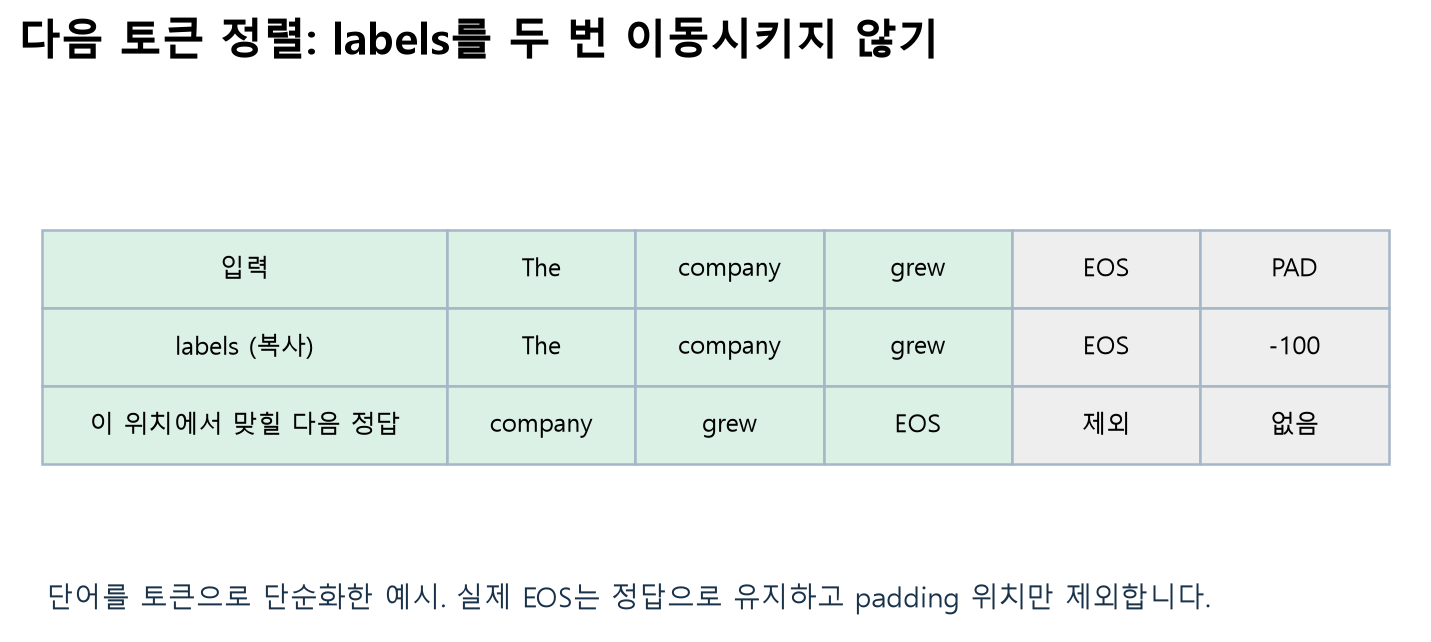

그림의 구조를 실제 출력과 대조하세요. 모든 문제는 예상·실행·근거 설명을 포함합니다. 문제용 빈칸은 기본 실험 변수를 바꾸지 않아, 아직 답하지 못해도 다음 기본 셀을 실행할 수 있습니다.


[Figure source](https://raw.githubusercontent.com/lunalab-ai/genAI/2026-fall-w09b/course/notion/w09b/assets/07-shift.png)


## 0. 설치와 준비

첫 셀은 고정한 수업 패키지를 설치합니다. `prepare_text_runtime()`은 별도 자식 Python으로 텍스트 모델 import를 점검하며, 설치돼 있지만 import가 실패한 선택 영상·음성 패키지만 현재 런타임에서 복구합니다. 정상 패키지와 torch는 유지합니다. 이전 모듈을 불러온 뒤 설치 버전을 바꿨다면 런타임을 재시작합니다.

모델/데이터 다운로드 실패는 오류로 표시합니다. 연결을 복구한 뒤 준비 셀을 다시 실행하면 완전한 캐시를 재사용합니다. 개인 PC의 비공개 경로를 Colab 입력으로 사용하지 않습니다.


In [ ]:
import sys, subprocess, os, json, math, time, uuid
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError
PUBLIC_REF='2026-fall-w09b'
try:
    ready=all(version(p)==v for p,v in [('luna-genai','0.1.15'),('datasets','4.8.5'),('transformers','5.15.1'),('gradio','6.26.0')])
except PackageNotFoundError:
    ready=False
if not ready:
    if 'luna_genai' in sys.modules:
        raise RuntimeError('이전 버전이 메모리에 남아 있습니다. 런타임을 재시작하고 첫 셀부터 실행하세요.')
    package=str(Path('src').resolve()) if Path('src/pyproject.toml').exists() else f'git+https://github.com/lunalab-ai/genAI.git@{PUBLIC_REF}#subdirectory=src'
    subprocess.run([sys.executable,'-m','pip','install','-q',package],check=True)
from luna_genai.runtime import prepare_text_runtime
removed_optional=prepare_text_runtime(repair_optional=True)
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from luna_genai.finetuning import FineTuningLab,load_news,text_key,classification_metrics,cross_entropy,causal_batch,target_table,instruction_record
from luna_genai.finetuning_app import build_finetuning_app,classification_view,generation_view,instruction_view
torch.set_num_threads(2)
IN_COLAB='COLAB_RELEASE_TAG' in os.environ
DEVICE='cpu'  # GPU 확장은 사용 가능한 무료 장치를 직접 선택한 경우에만 cuda로 변경
print('Python',sys.version.split()[0],'package',version('luna-genai'),'device',DEVICE,'CUDA available',torch.cuda.is_available())
print('정상적인 선택 패키지는 유지합니다. 제거한 비호환 선택 패키지:',removed_optional)


## 1. Business 문서와 원래 라벨 열

[`load_news()`](https://github.com/lunalab-ai/genAI/blob/2026-fall-w09b/src/W09B-API.md)의 고정 원본에서 Business 문서를 골라 id/text만 남깁니다. CPU 필수 경로는 학습128·validation16·최종 test16문서와 최대32토큰을 사용합니다. 짧은 실제 갱신은 이 중 소수 배치만 사용합니다. 문서 수와 실제 학습 단계 수를 혼동하지 마세요.


In [ ]:
news=load_news(train_per_class=128,validation_per_class=16,test_per_class=16)
business={split:[{'id':r['id'],'text':r['text']} for r in news[split] if r['label']==2] for split in ('train','validation','test')}
display(pd.DataFrame([{'split':k,'documents':len(v),'fields':list(v[0])} for k,v in business.items()]))
print(news['provenance'])


### B1 · 확장

원래 주제 라벨 열을 제거한 다음, 생성 학습에서 labels는 어떻게 만들어질까요? 다른 주제의 뉴스로 바꿀 때 달라지는 것과 그대로인 것을 설명하세요.

**힌트:** 주제 라벨은 문장당 하나였고 다음 토큰의 정답은 문장 안에 있습니다.

**자가 점검:** 예상·관찰·이유를 구별하고, 바꾼 조건과 고정한 조건을 적었나요?


## 2. 토큰·EOS·padding·다음 토큰 정렬

[`FineTuningLab('causal',max_length=32)`](https://github.com/lunalab-ai/genAI/blob/2026-fall-w09b/src/W09B-API.md)는 SmolLM-135M을 준비합니다. `batch()`는 가변 길이 텍스트에 실제 EOS를 붙이고 마스크0만 loss에서 제외합니다. `target_table()`은 모델 손실에서 대응할 다음 토큰을 보여 주며 전달받은 텐서를 이동시키지 않습니다.

아래 두 문장은 직접 만든 구조 관찰용 예문입니다. labels는 입력과 같은 크기이고 logits는 각 위치에서49,152개 어휘의 점수를 가집니다.


In [ ]:
lab=FineTuningLab('causal',device=DEVICE,seed=42,max_length=32)
display(lab.state())
examples=[{'text':'The company grew quickly.'},{'text':'Profit rose.'}]
batch=lab.batch(examples)
print('EOS ID',lab.tokenizer.eos_token_id,'PAD ID',lab.tokenizer.pad_token_id)
for name,tensor in batch.items():print(name,tuple(tensor.shape),tensor)
display(target_table(batch,lab.tokenizer,row=1))
with torch.inference_mode():
    inspected=lab.model(**batch,output_hidden_states=True)
print('hidden:',tuple(inspected.hidden_states[-1].shape),'logits:',tuple(inspected.logits.shape),'loss:',float(inspected.loss))


### B2 · 필수

다음 두 오류를 고치세요: ① input_ids==pad_token_id인 모든 위치의 labels를 지움 ② labels를 한 번 이동한 뒤 모델에도 labels로 전달함.

**힌트:** 실제 EOS와 padding은 같은 ID여도 위치의 역할이 다릅니다. 모델 내부에서 한 번 정렬합니다.

**자가 점검:** 예상·관찰·이유를 구별하고, 바꾼 조건과 고정한 조건을 적었나요?


## 3. 손실의 분모와 현재 모델에서의 검산

각 배치의 유효한 다음 토큰 수를 $n_b$라 하면 전체 NLL은 $\sum_b n_b L_b/\sum_b n_b$입니다. `evaluate()`는 padding을 제외한 유효 토큰 수로 가중합니다. 같은 토크나이저·입력 길이·분할에서 전후를 비교합니다. 낮은 NLL과 좋은 사실성·지시 이행은 별개입니다.


### B3 · 확장

유효 토큰2개의 평균 손실이2, 토큰8개의 평균 손실이4일 때 전체 NLL을 계산하세요. 위 실제 batch의 model.loss도 한 칸 정렬한 cross-entropy와 대조하세요.

**힌트:** 문서 수가 아니라 무시하지 않는 다음 토큰 위치의 수로 가중합니다.

**자가 점검:** 예상·관찰·이유를 구별하고, 바꾼 조건과 고정한 조건을 적었나요?


## 4. 같은 조건에서 학습 전후 비교

`evaluate()`는 가중치를 바꾸지 않고 실제 토큰 NLL·PPL·유효 토큰 수를 반환합니다. `generate()`는 프롬프트 뒤의 새 부분과 실행 설정을 반환합니다. 먼저 baseline을 보존하고4회 실제 갱신 뒤 같은 문서·프롬프트·설정으로 비교합니다.

학습률5e-5·batch1·최대32토큰은 CPU 실측 후 정한 원리 관찰용 예산입니다. 학습 손실 감소나 출력 변화는 보장하지 않습니다. 같은 greedy 문장이 나와도 가중치·확률이 달라졌을 수 있습니다. 충분한 학습과 통계적으로 안정된 성능 평가는 별도입니다.


In [ ]:
PROMPT='The company announced'
print('시작 문장 뜻: 그 회사는 발표했다')
before=lab.evaluate(business['validation'],batch_size=2)
before_text=lab.generate(PROMPT,max_new_tokens=12,temperature=0,seed=42)
STEPS=4
training=lab.fit(business['train'],steps=STEPS,batch_size=1,learning_rate=5e-5)
after=lab.evaluate(business['validation'],batch_size=2)
after_text=lab.generate(PROMPT,max_new_tokens=12,temperature=0,seed=42)
display(pd.DataFrame([{'phase':'before',**before},{'phase':'after',**after}]))
display(pd.DataFrame(training['history']))
print('학습 전:',before_text['text']);print('학습 후:',after_text['text'])
print('지정 파라미터 일부의 실제 변화:',training['parameter_probe_l2_changes'])


### B4 · 확장

학습 전후와 temperature 변경 실험에서 고정할 조건을 각각 설명하세요. greedy 출력이 같으면 학습하지 않았다고 결론 내릴 수 있나요?

**힌트:** argmax 토큰이 같아도 전체 분포는 바뀔 수 있습니다. greedy에서는 seed가 토큰 선택을 바꾸지 않습니다.

**자가 점검:** 예상·관찰·이유를 구별하고, 바꾼 조건과 고정한 조건을 적었나요?


## 5. 지시 데이터 형식화와 실제 학습 구별

[`instruction_record(instruction,text,response)`](https://github.com/lunalab-ai/genAI/blob/2026-fall-w09b/src/W09B-API.md)는 사용자가 제공한 세 문자열을 검사하고 직렬화합니다. 정답을 만들어 주거나 사실성을 검증하거나 SFT를 실행하지 않습니다. 여러 작업의 지시를 학습하고 보지 않은 문서/지시에서 평가하는 원리를 [지시 사항 노트](https://github.com/lunalab-ai/genAI/blob/2026-fall-w09b/course/notion/w09b/w09b-instructions.md)와 연결합니다.


In [ ]:
demo_record=instruction_record('Rewrite the sentence as a short headline.','A company opened a new office in the city.','Company Opens New City Office')
print(demo_record['serialized']);print(demo_record['status'])
my_instruction=None
my_input=None
my_response=None


### B5 · 필수

자신의 새 뉴스 예문에 지시·입력·목표 응답을 작성하고 학습에 쓰지 않을 평가 사례를 만드세요. 같은 원문에 지시문만 바꾼 예제를 train/test로 나눠도 될까요? 평가의 내용·형식 기준을 함께 설명하세요.

**힌트:** 문서부터 분리하고, 형식화·학습·평가를 따로 기록합니다.

**자가 점검:** 예상·관찰·이유를 구별하고, 바꾼 조건과 고정한 조건을 적었나요?


## 6. 나의 함수와 마지막 웹앱 연결

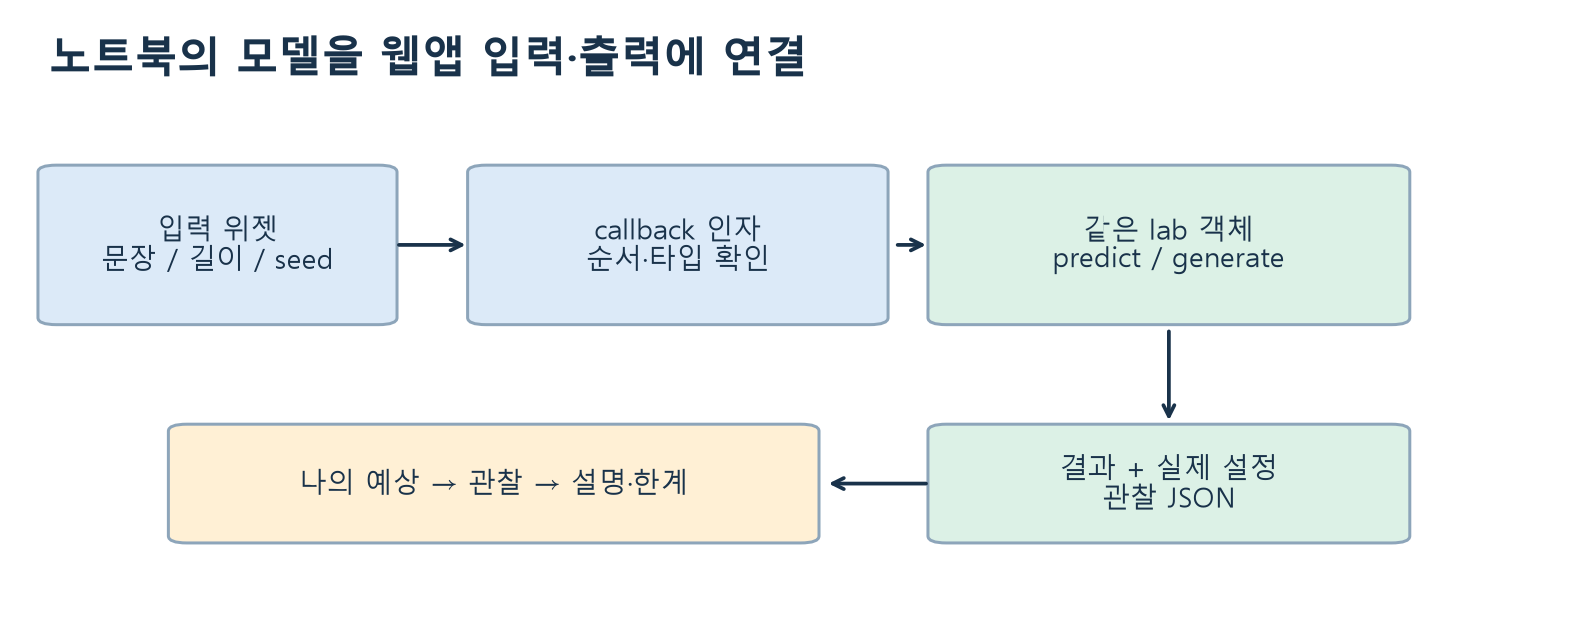

[`build_finetuning_app(lab,summary_fn)`](https://github.com/lunalab-ai/genAI/blob/2026-fall-w09b/src/W09B-API.md)는 모델을 새로 로드하거나 학습하지 않고 앱을 만듭니다. 모델 입력·지시 데이터·실험 설명의 세 탭이 있습니다. summary_fn은 예상/관찰/설명 세 문자열을 받아 한 문자열을 반환하는 자신의 함수입니다. 빈칸을 아직 작성하지 않으면 기본 기록기를 사용한다고 명시하고 실제 모델 실험은 계속할 수 있습니다.


[Figure source](https://raw.githubusercontent.com/lunalab-ai/genAI/2026-fall-w09b/course/notion/w09b/assets/09-app.png)


In [ ]:
learner_note=None  # 자신의 함수로 바꾸세요. 아래 기본 모델 실험과는 분리된 연습 변수입니다.


### B6 · 필수

예상·관찰·설명을 받아 근거와 한계를 정리하는 함수를 작성하고 세 위젯과 출력에 연결하세요. 위젯 순서를 바꾼 경우 무엇을 고쳐야 하는지도 설명하세요.

**힌트:** 함수를 먼저 직접 호출하고 인자3개와 반환 문자열을 확인합니다.

**자가 점검:** 예상·관찰·이유를 구별하고, 바꾼 조건과 고정한 조건을 적었나요?


In [ ]:
print('나의 함수 연결' if callable(learner_note) else '기본 앱 사용 중 · 나의 설명 함수는 아직 미연결')
app=build_finetuning_app(lab,summary_fn=learner_note)
final_test=lab.evaluate(business['test'],batch_size=2)
display(final_test)
view=generation_view(lab,PROMPT,8,0,42)
print(view[0]);display(view[1])
design=instruction_view('Write a headline.','A new shop opened.','New Shop Opens')
print(design[0]);print(design[1])
if IN_COLAB:
    app.queue().launch(share=True,inline=True,prevent_thread_lock=True,show_error=True)
    print('새 탭에서 앱을 열어 각 버튼을 누르세요:',app.share_url)


In [ ]:
keys={k:{text_key(r['text']) for r in business[k]} for k in ('train','validation','test')}
assert not(keys['train']&keys['validation'] or keys['train']&keys['test'] or keys['validation']&keys['test'])
assert tuple(batch['labels'].shape)==tuple(batch['input_ids'].shape)
assert inspected.logits.shape[-1]==49152 and inspected.hidden_states[-1].shape[-1]==576
assert (batch['labels'][batch['attention_mask']==0]==-100).all()
assert all(np.isfinite(r['loss']) for r in training['history']) and lab.steps==STEPS
assert all(v>0 for v in training['parameter_probe_l2_changes'].values())
assert np.isfinite(after['nll']) and after['target_tokens']==before['target_tokens']>0
assert before_text['text'].strip() and after_text['text'].strip() and view[0].strip()
assert before_text['prompt']==after_text['prompt'] and before_text['max_new_tokens']==after_text['max_new_tokens']
assert view[1]['state']['steps']==STEPS and Path(view[2]).is_file()
assert 'SFT 학습하지 않음' in design[1] and len(app.config['dependencies'])>=3
observation={'source':news['provenance'],'rows':{k:len(v) for k,v in business.items()},'before':before,'after':after,'test':final_test,'training':training,'generation_before':before_text,'generation_after':after_text,'instruction_activity':'formatting only; no SFT training'}
folder=Path('.build/w09b-observations');folder.mkdir(parents=True,exist_ok=True)
(folder/f'B-{uuid.uuid4().hex[:8]}.json').write_text(json.dumps(observation,ensure_ascii=False,indent=2),encoding='utf-8')
print('W09B B 검증 통과 · 실제 생성 학습/정답 정렬/평가/모델 callback · 지시 형식화와 SFT 구별')
